In [1]:
# 0. Instalação das dependências (rode apenas uma vez)
!pip install pandas numpy matplotlib seaborn scikit-learn -q

In [2]:
# 1. Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração para que os gráficos fiquem mais bonitos por padrão
sns.set_theme(style="whitegrid")

In [3]:
# 2. Carregamento do dataset
caminho_arquivo = '../data/raw/food_delivery_orders_dataset.csv'
df = pd.read_csv(caminho_arquivo)

# Converter colunas de data/hora para o formato correto
df['order_timestamp'] = pd.to_datetime(df['order_timestamp'])
df['order_date'] = pd.to_datetime(df['order_date'])

# Exibindo as primeiras linhas para visão geral
display(df.head())

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [4]:
# Verificando as dimensões (linhas, colunas)
print(f"O dataset possui {df.shape[0]} linhas e {df.shape[1]} colunas.\n")

# Identificando os tipos de dados e valores ausentes
df.info()

O dataset possui 50000 linhas e 37 colunas.

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_id                             50000 non-null  str           
 1   customer_id                          50000 non-null  str           
 2   restaurant_id                        50000 non-null  str           
 3   driver_id                            50000 non-null  str           
 4   order_timestamp                      50000 non-null  datetime64[us]
 5   order_date                           50000 non-null  datetime64[us]
 6   order_hour                           50000 non-null  int64         
 7   day_of_week                          50000 non-null  str           
 8   is_weekend                           50000 non-null  int64         
 9   city                                 50000 non-nu

In [5]:
# 4. Resumo estatístico das variáveis numéricas
display(df.describe())

# Resumo das variáveis categóricas (corrigido para evitar o Pandas4Warning)
display(df.describe(include=['object', 'str']))

,order_timestamp,order_date,order_hour,is_weekend,customer_age,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,...,order_total,tip_amount,distance_km,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,customer_rating
count,50000,50000,50000.000000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,...,50000.000000,49132.000000,50000.000000,50000.0000,50000.000000,50000.000000,50000.000000,49132.000000,49132.000000,49132.000000
mean,2025-10-16 04:28:15.081600,2025-10-15 13:30:58.751999,14.465900,0.26712,27.686580,4.207956,2.91002,30.897938,4.495700,4.128796,...,38.169501,1.610076,4.730632,29.7332,4.495062,15.549600,30.950580,35.152365,0.365709,4.295946
min,2025-10-01 00:00:00,2025-10-01 00:00:00,0.000000,0.00000,18.000000,2.800000,1.00000,5.100000,0.000000,0.570000,...,4.870000,0.000000,0.800000,1.0000,3.200000,5.000000,8.000000,10.000000,0.000000,1.800000
25%,2025-10-08 15:00:30,2025-10-08 00:00:00,11.000000,0.00000,21.000000,3.900000,1.00000,13.100000,0.000000,1.730000,...,17.430000,0.000000,2.800000,14.0000,4.300000,10.000000,22.000000,25.000000,0.000000,4.000000
50%,2025-10-16 09:24:00,2025-10-16 00:00:00,14.000000,0.00000,27.000000,4.200000,2.00000,22.825000,0.000000,2.890000,...,28.350000,0.000000,4.100000,29.0000,4.500000,14.000000,28.000000,33.000000,0.000000,4.400000
75%,2025-10-23 16:52:15,2025-10-23 00:00:00,19.000000,1.00000,33.000000,4.600000,4.00000,40.120000,10.000000,5.390000,...,48.660000,2.280000,5.900000,44.0000,4.800000,19.000000,37.000000,42.000000,1.000000,4.700000
max,2025-10-30 23:59:00,2025-10-30 00:00:00,23.000000,1.00000,55.000000,5.000000,10.00000,362.980000,20.000000,50.820000,...,443.210000,53.650000,20.000000,60.0000,5.000000,73.000000,128.000000,172.000000,1.000000,5.000000
std,NaN,NaN,5.231155,0.44246,7.537796,0.450977,2.02907,27.068965,6.430008,3.636275,...,31.054669,2.878464,2.780190,17.4052,0.349198,7.360099,12.825519,14.701154,0.481633,0.530947


,order_id,customer_id,restaurant_id,driver_id,day_of_week,city,delivery_area,customer_type,restaurant_type,restaurant_primary_category,payment_method,weather,traffic_level,order_status,cancellation_reason
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,868
unique,50000,4979,250,200,7,4,40,3,4,6,3,4,3,2,5
top,ORD_000001,CUS_00001,RES_0001,DRV_0066,Thursday,City_A,City_A_Area_1,Regular,Fast Food,Burger,Credit Card,Clear,Medium,Completed,Driver Unassigned
freq,1,4510,8837,315,8472,19888,2056,25098,27593,16184,24971,28248,19522,49132,386


In [6]:
# 5. Identificação e quantificação de valores ausentes
valores_ausentes = df.isnull().sum()
porcentagem_ausentes = (df.isnull().sum() / len(df)) * 100

# Criando uma tabela para facilitar a visualização
tabela_ausentes = pd.DataFrame({'Quantidade': valores_ausentes, 'Porcentagem (%)': porcentagem_ausentes})

# Exibindo apenas as colunas que possuem algum valor ausente
display(tabela_ausentes[tabela_ausentes['Quantidade'] > 0])

# Preencher os motivos de cancelamento vazios para os pedidos concluídos
df['cancellation_reason'] = df['cancellation_reason'].fillna('Não Cancelado')

# Criar um dataset apenas com pedidos concluídos para a análise de tempo de entrega
df_concluido = df[df['order_status'] == 'Completed']

,Quantidade,Porcentagem (%)
tip_amount,868,1.736
actual_delivery_time_minutes,868,1.736
late_delivery,868,1.736
cancellation_reason,49132,98.264
customer_rating,868,1.736


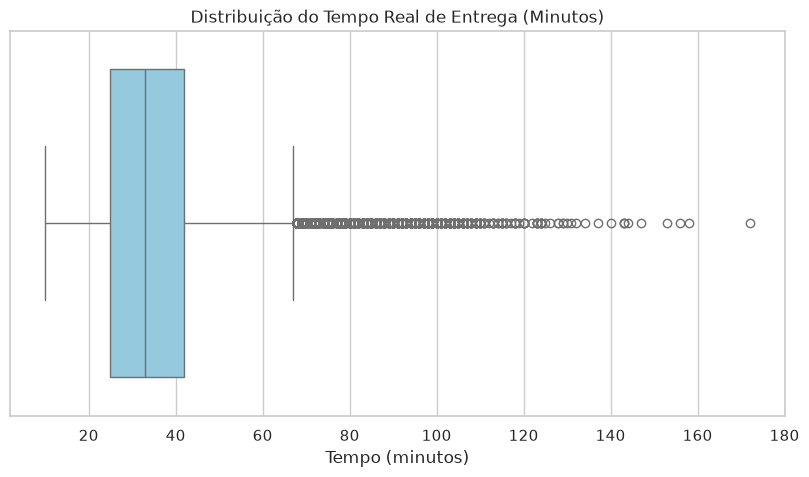

In [7]:
# 6. Detecção visual de Outliers
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['actual_delivery_time_minutes'], color='skyblue')
plt.title('Distribuição do Tempo Real de Entrega (Minutos)')
plt.xlabel('Tempo (minutos)')
plt.show()

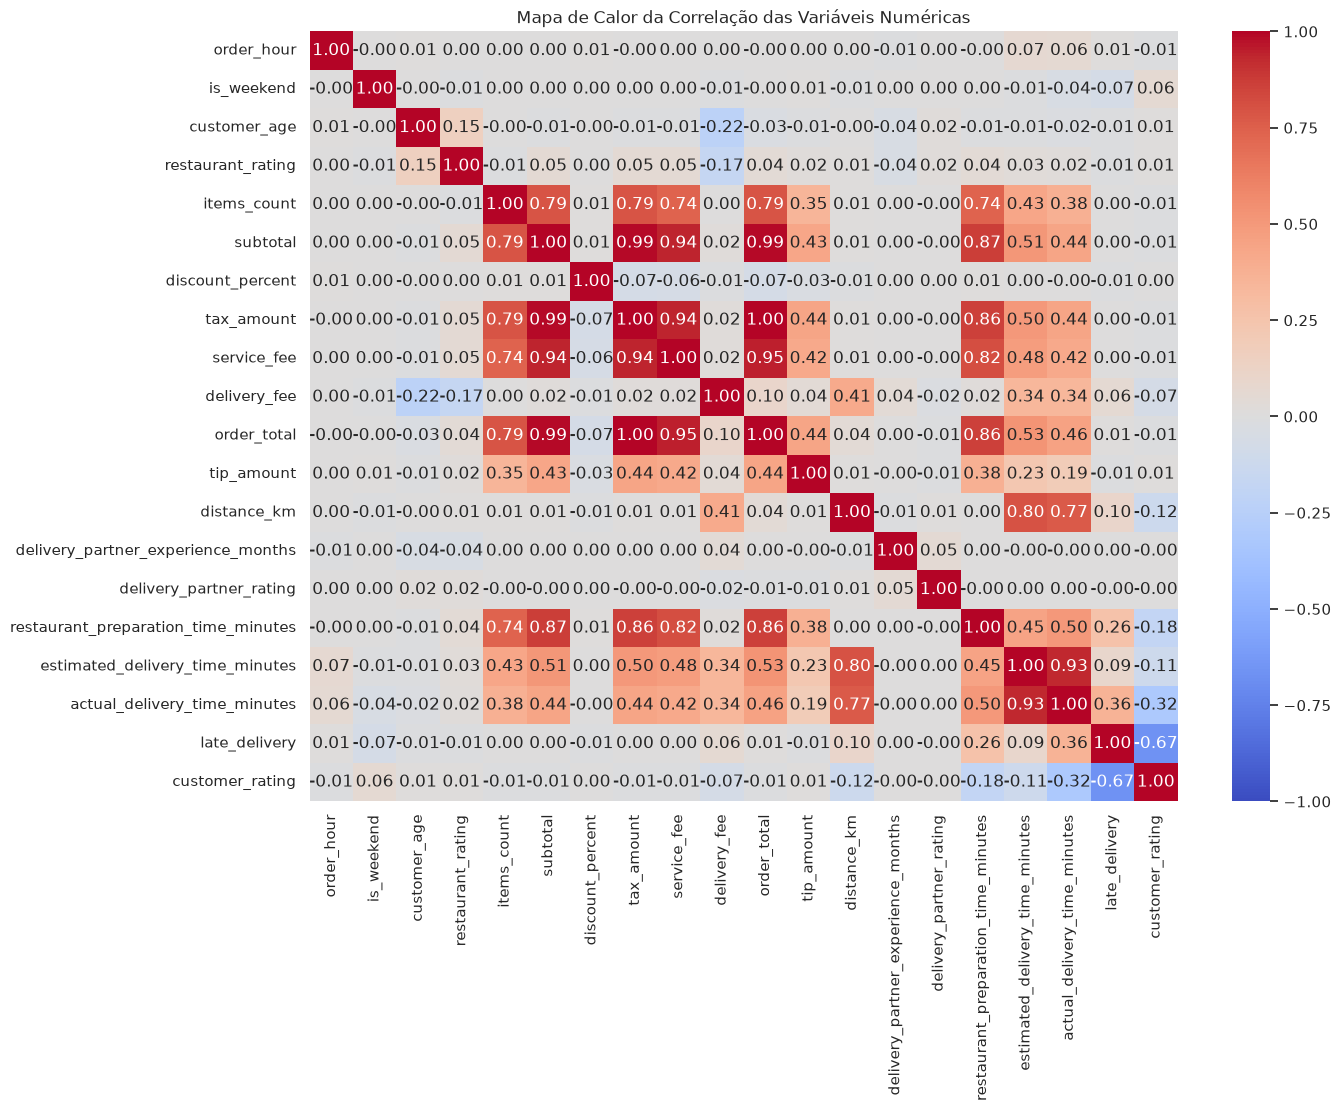

In [8]:
# 7. Análise de Correlação
# Selecionamos apenas as colunas numéricas, pois não faz sentido correlacionar textos
colunas_numericas = df.select_dtypes(include=['int64', 'float64'])

# Calculamos a matriz de correlação já arredondando para 2 casas decimais
matriz_correlacao = colunas_numericas.corr().round(2)

# Gerando o Heatmap (Mapa de Calor)
plt.figure(figsize=(14, 10))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Mapa de Calor da Correlação das Variáveis Numéricas')
plt.show()

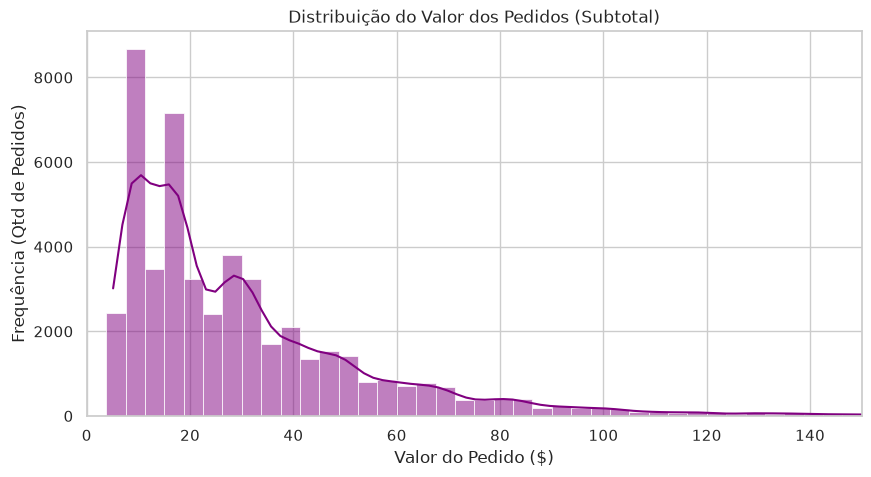

In [9]:
# 8.1 Visualização 1: Histograma - Distribuição do Valor dos Pedidos (Subtotal)
plt.figure(figsize=(10, 5))
# Focando a visão nos pedidos de até 150 dólares para melhorar o visual
sns.histplot(data=df, x='subtotal', bins=40, kde=True, color='purple', binrange=(0, 150))
plt.title('Distribuição do Valor dos Pedidos (Subtotal)')
plt.xlabel('Valor do Pedido ($)')
plt.ylabel('Frequência (Qtd de Pedidos)')
plt.xlim(0, 150) # Corta o eixo X para dar zoom na parte importante
plt.show()

/tmp/ipykernel_69960/2259320697.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='day_of_week', palette='viridis', order=ordem_dias)


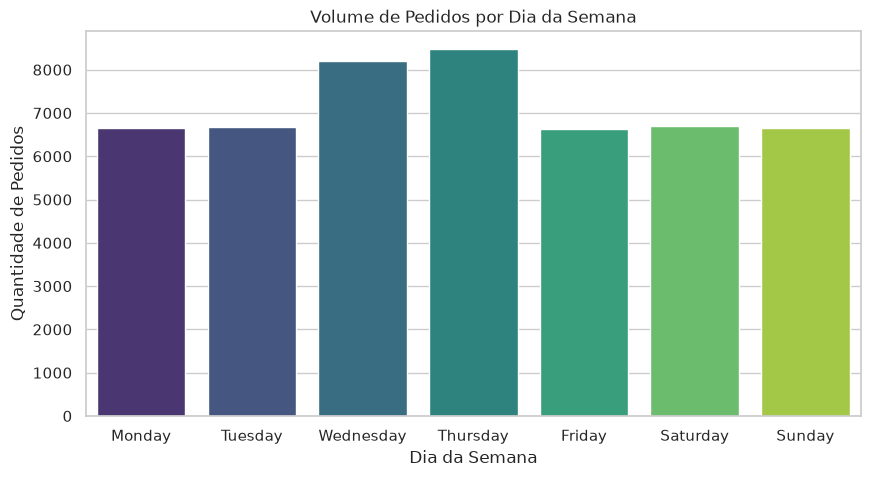

In [10]:
# 8.2 Visualização 2: Gráfico de Barras - Volume de Pedidos por Dia da Semana
plt.figure(figsize=(10, 5))
ordem_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df, x='day_of_week', palette='viridis', order=ordem_dias)
plt.title('Volume de Pedidos por Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Quantidade de Pedidos')
plt.show()

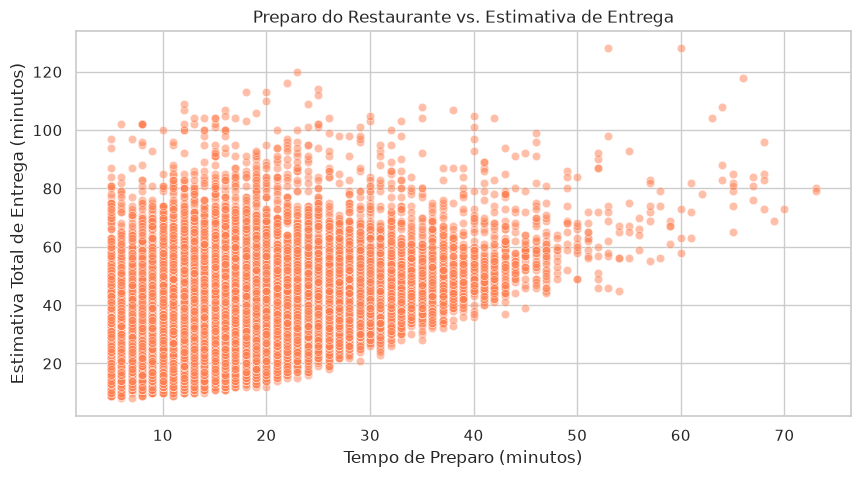

In [11]:
# 8.3 Visualização 3: Scatter Plot - Relação entre Tempo de Preparo e Tempo Total Estimado
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='restaurant_preparation_time_minutes', y='estimated_delivery_time_minutes', alpha=0.5, color='coral')
plt.title('Preparo do Restaurante vs. Estimativa de Entrega')
plt.xlabel('Tempo de Preparo (minutos)')
plt.ylabel('Estimativa Total de Entrega (minutos)')
plt.show()

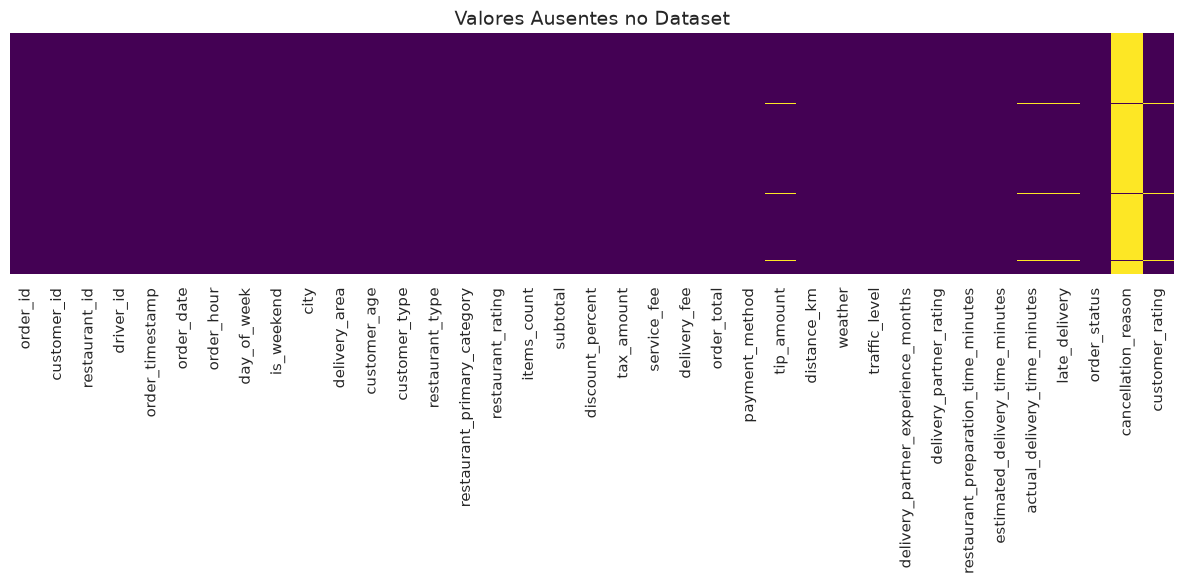

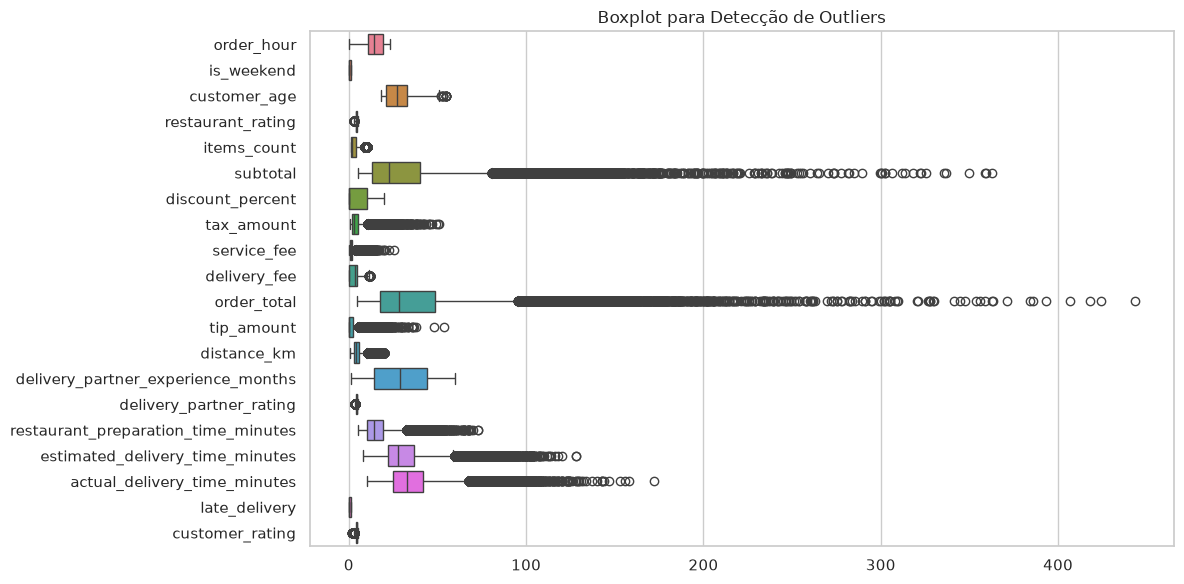

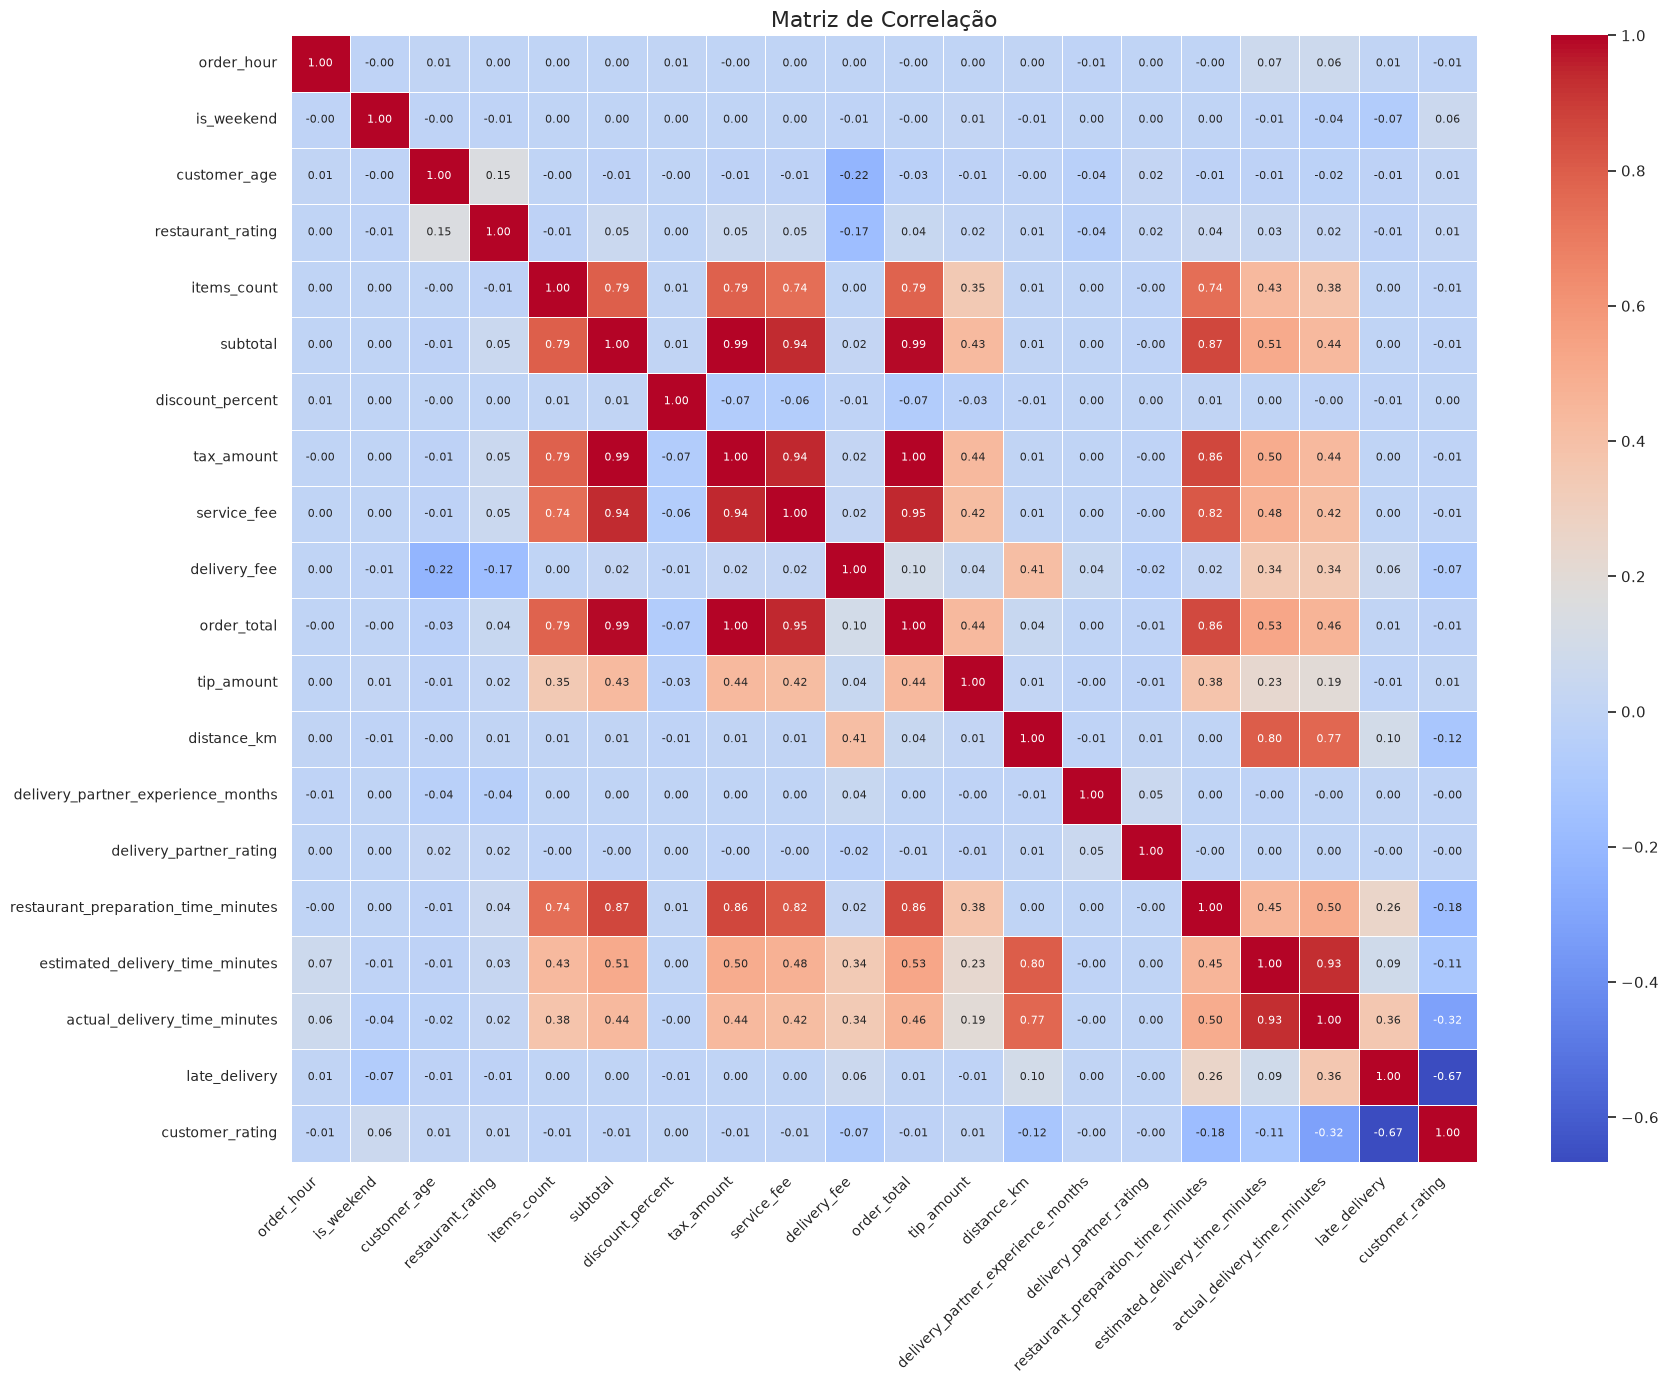

In [12]:
import sys
import os
import pandas as pd

# Avisa ao Python para procurar módulos na pasta anterior (raiz do projeto)
sys.path.append(os.path.abspath('..'))

# Agora a importação vai funcionar perfeitamente!
from src.visualization import plot_missing_values, plot_outliers_boxplot, plot_correlation_matrix

# 1. Carregando o dataset bruto original
df = pd.read_csv('../data/raw/food_delivery_orders_dataset.csv')

# 2. Gerando e salvando as imagens na pasta reports/figures/
plot_missing_values(df)
plot_outliers_boxplot(df)
plot_correlation_matrix(df)